In [1]:
!pip install -q datasets

import numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from datasets import load_dataset

# Cats vs Dogs dataset (~23k images) from Hugging Face - no login needed
raw = load_dataset("microsoft/cats_vs_dogs", split="train")
class_names = raw.features["labels"].names      # ['cat', 'dog']
print("Classes:", class_names, "| Total images:", len(raw))

# 80% train / 20% validation (stratified, fixed seed)
split = raw.train_test_split(test_size=0.2, seed=42, stratify_by_column="labels")

README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

Classes: ['cat', 'dog'] | Total images: 23410


In [2]:
IMG_SIZE = (128, 128)
BATCH = 32

def to_arrays(hf_split):
    X = np.empty((len(hf_split), *IMG_SIZE, 3), dtype=np.uint8)
    y = np.empty((len(hf_split), 1), dtype=np.float32)
    for i, ex in enumerate(hf_split):
        X[i] = np.asarray(ex["image"].convert("RGB").resize(IMG_SIZE))
        y[i] = ex["labels"]
    return X, y

X_train, y_train = to_arrays(split["train"])
X_val,   y_val   = to_arrays(split["test"])
print("Train:", X_train.shape, "| Validation:", X_val.shape)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(5000, seed=42).batch(BATCH).prefetch(AUTOTUNE))
val_ds   = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
            .batch(BATCH).prefetch(AUTOTUNE))       # no shuffle -> order stays fixed

Train: (18728, 128, 128, 3) | Validation: (4682, 128, 128, 3)


In [3]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    data_aug,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(256, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,420,993 (5.42 MB)

 Trainable params: 1,420,993 (5.42 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=[early_stop])

Epoch 1/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.5996 - loss: 0.6596 - val_accuracy: 0.5970 - val_loss: 0.6911
Epoch 2/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.6948 - loss: 0.5837 - val_accuracy: 0.7302 - val_loss: 0.5424
Epoch 3/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7404 - loss: 0.5222 - val_accuracy: 0.7693 - val_loss: 0.4812
Epoch 4/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7688 - loss: 0.4870 - val_accuracy: 0.8095 - val_loss: 0.4102
Epoch 5/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7857 - loss: 0.4558 - val_accuracy: 0.7962 - val_loss: 0.4245
Epoch 6/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.8093 - loss: 0.4174 - val_accuracy: 0.8486 - val_loss: 0.3475
Epoch 7/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.8208 - loss: 0.3978 - val_accuracy: 0.7839 - val_loss: 0.4787
Epoch 8/40
586/586 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.8333 - loss: 0.3750 - 

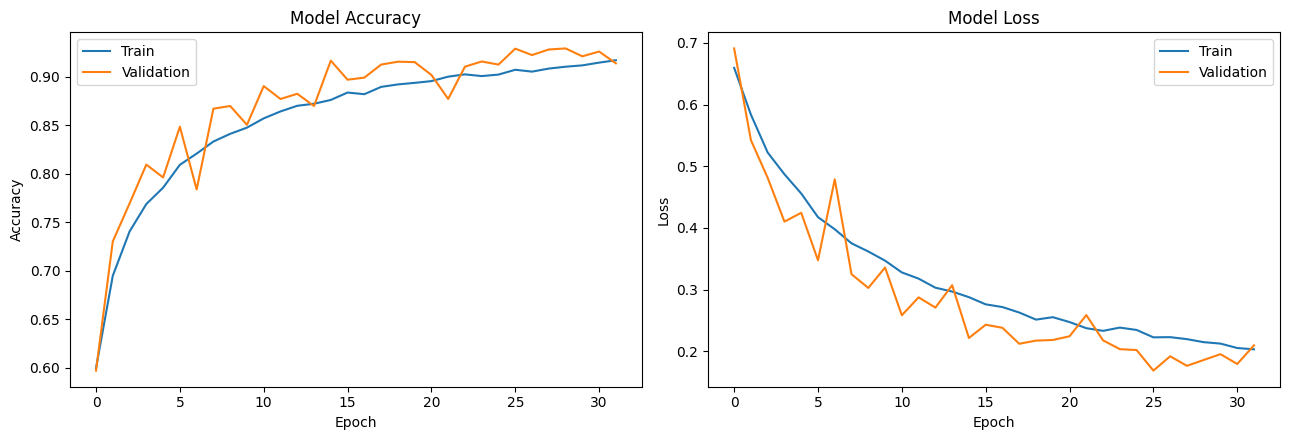

In [5]:
# Accuracy and Loss graphs
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(history.history["accuracy"], label="Train")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Model Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend()

ax[1].plot(history.history["loss"], label="Train")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Model Loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()

plt.tight_layout(); plt.show()

147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Validation Loss: 0.1685 | Validation Accuracy: 0.9291



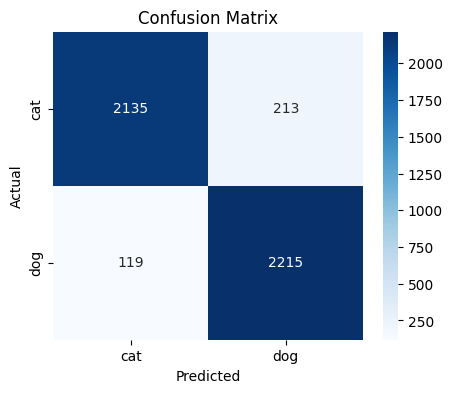

Classification Report:

              precision    recall  f1-score   support

         cat     0.9472    0.9093    0.9279      2348
         dog     0.9123    0.9490    0.9303      2334

    accuracy                         0.9291      4682
   macro avg     0.9297    0.9291    0.9291      4682
weighted avg     0.9298    0.9291    0.9291      4682



In [6]:
# Predictions on validation set (shuffle=False keeps order consistent)
y_true = np.concatenate([y.numpy() for _, y in val_ds]).ravel().astype(int)
y_prob = model.predict(val_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation Loss: {loss:.4f} | Validation Accuracy: {acc:.4f}\n")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

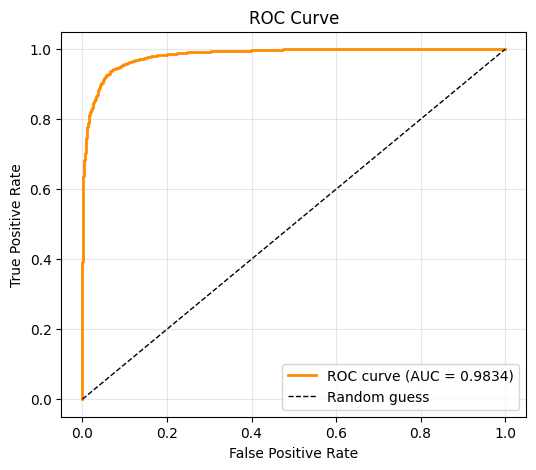

In [7]:
# ROC Curve and AUC
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()